# Poster NeRF

Training the real Poster dataset with hierarchical sampling, a deeper MLP, integrated positional encoding and distortion regularization.

In [3]:
from pathlib import Path
import json
import math
import time

import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn.functional as F
from pytorch3d.renderer import (
    PerspectiveCameras,
    MonteCarloRaysampler,
    NDCMultinomialRaysampler,
    EmissionAbsorptionRaymarcher,
    RayBundle,
    ray_bundle_to_ray_points,
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


## Data

The 226 Poster images and calibrated camera parameters are loaded using the original dataset pipeline.

In [ ]:
data_dir = Path("data/poster")
image_folder = "images"

ARCH = "deep"
USE_IPE = True
LAMBDA_DIST = 1e-3
TRAIN = True
RENDER_TEST = True

N_ITER = 20000
BATCH_SIZE = 3
N_RAYS = 750
RAY_CHUNK = 250
N_COARSE = 64
N_FINE = 128
LR = 1e-3
MIN_DEPTH = 0.01
MAX_DEPTH = 32.0

assert ARCH in ("shallow", "deep")
assert not USE_IPE or ARCH == "deep"
assert LAMBDA_DIST >= 0
assert N_RAYS % RAY_CHUNK == 0

run_name = f"poster_outputs_hierarchical_{ARCH}"
if USE_IPE:
    run_name += "_ipe"
if LAMBDA_DIST > 0:
    run_name += f"_dist_{LAMBDA_DIST:g}"
output_dir = Path(run_name)
output_dir.mkdir(exist_ok=True)

with (data_dir / "transforms.json").open() as file:
    transforms = json.load(file)

frames = sorted(transforms["frames"], key=lambda frame: frame["file_path"])
frame_ids = [Path(frame["file_path"]).name for frame in frames]
print("Images:", len(frames), "Output:", output_dir)

for folder in ["images", "images_2", "images_4", "images_8"]:
    with Image.open(data_dir / folder / frame_ids[0]) as image:
        print(folder, image.size)

Images: 226 Output: poster_outputs_hierarchical_deep_ipe_dist_0.001
images (1080, 1920)
images_2 (540, 960)
images_4 (270, 480)
images_8 (135, 240)


The Poster camera transformations and `applied_transform` handling are unchanged from the original notebook.

In [5]:
def load_nerf_data(data_dir, image_folder):   
    with open(data_dir / "transforms.json") as f:   
        transforms_data = json.load(f)  

     
    frames = sorted(transforms_data["frames"], key=lambda frame: frame["file_path"])   
    
    first_image = data_dir / image_folder / Path(frames[0]["file_path"]).name  
    with Image.open(first_image) as img:   
        width, height = img.size  
     
  
    # Keep one copy of the images in RAM   
    target_images = torch.empty(   
        (len(frames), height, width, 3),
        dtype=torch.float32,   
    )   
   
  
   
    Rs, Ts = [], []    
    axis_change = torch.diag(torch.tensor([-1.0, 1.0, -1.0]))   
     
  
    for index, frame in enumerate(frames):
        img_path = data_dir / image_folder / Path(frame["file_path"]).name    
     
        with Image.open(img_path) as img:    
            img_np = np.array(img).astype(np.float32) / 255.0    
   
        target_images[index] = torch.from_numpy(img_np)   
   
    
        c2w = torch.tensor(frame["transform_matrix"], dtype=torch.float32)   
        R_nerf = c2w[:3, :3]  
        T_nerf = c2w[:3, 3]   

        # Convert the saved camera axes to PyTorch3D    
        R_pytorch3d = R_nerf @ axis_change   
        T_pytorch3d = -T_nerf @ R_pytorch3d  
        Rs.append(R_pytorch3d)  
        Ts.append(T_pytorch3d)  



    scale_x = width / transforms_data["w"]   
    scale_y = height / transforms_data["h"]   

 
    target_cameras = PerspectiveCameras( 
        R=torch.stack(Rs),    
        T=torch.stack(Ts),   
        focal_length=((    
            transforms_data["fl_x"] * scale_x,  
            transforms_data["fl_y"] * scale_y, 
        ),),
        principal_point=((
            transforms_data["cx"] * scale_x,
            transforms_data["cy"] * scale_y,
        ),),
        image_size=((height, width),),
        in_ndc=False,
    )
   
    return target_images, target_cameras   

Train: 203 Test: 23


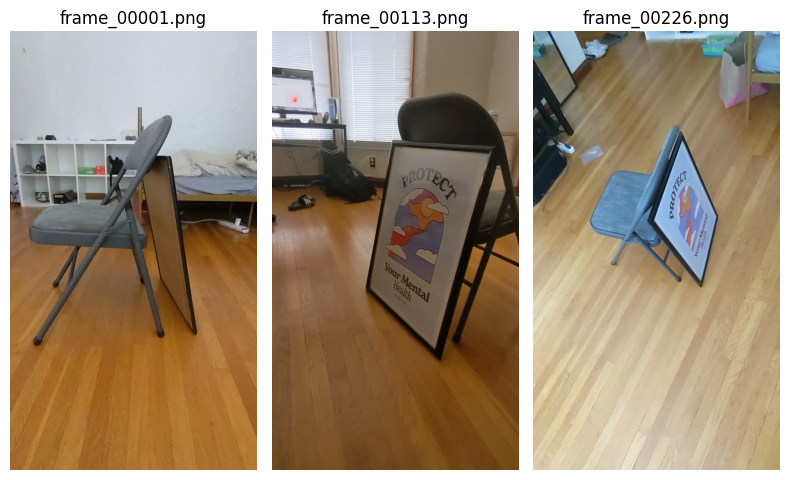

In [6]:
target_images, target_cameras = load_nerf_data(data_dir, image_folder)   
image_height, image_width = target_images.shape[1:3]  
     


# Every tenth image is kept for testing    
indices = torch.arange(len(frames)) 
test_indices = indices[indices % 10 == 1]  
train_indices = indices[indices % 10 != 1]  

print("Train:", len(train_indices), "Test:", len(test_indices))   
  

   

fig, axes = plt.subplots(1, 3, figsize=(8, 5))   

for ax, index in zip(axes, [0, 112, 225]):  
    ax.imshow(target_images[index])   
    ax.set_title(frame_ids[index])
    ax.axis("off")  
   

plt.tight_layout()   
plt.show()   

## Model

The original shallow NeRF is retained below for reference. The combined experiment uses the deeper NeRF MLP with coarse/fine sampling, IPE and distortion loss.

In [7]:
class HarmonicEmbedding(torch.nn.Module):    

    def __init__(self, n_harmonic_functions):    

        super().__init__()   
        self.register_buffer(  
            'frequencies',   
            2.0 ** torch.arange(n_harmonic_functions),   
        )  


    def forward(self, x):   
        embed = (x[..., None] * self.frequencies).view(*x.shape[:-1], -1)  
        return torch.cat((x, embed.sin(), embed.cos()), dim=-1)   
  
     


class NeuralRadianceField(torch.nn.Module):  
    def __init__(self, n_hidden_neurons=256):    
        super().__init__()    
   
        self.position_embedding = HarmonicEmbedding(10)   
        self.direction_embedding = HarmonicEmbedding(4)   
  
        position_dim = 3 + 10 * 2 * 3  
        direction_dim = 3 + 4 * 2 * 3
  

        self.mlp = torch.nn.Sequential(    
            torch.nn.Linear(position_dim, n_hidden_neurons),
            torch.nn.Softplus(beta=10.0),
            torch.nn.Linear(n_hidden_neurons, n_hidden_neurons),   
            torch.nn.Softplus(beta=10.0),
        )



        self.color_layer = torch.nn.Sequential(      
            torch.nn.Linear(n_hidden_neurons + direction_dim, n_hidden_neurons),
            torch.nn.Softplus(beta=10.0),
            torch.nn.Linear(n_hidden_neurons, 3),
            torch.nn.Sigmoid(),

        )  


        self.density_layer = torch.nn.Sequential(    
            torch.nn.Linear(n_hidden_neurons, 1),  
            torch.nn.Softplus(beta=10.0),   

        )

        self.density_layer[0].bias.data[0] = -1.5    

    def _get_densities(self, features, ray_bundle):   
        raw_densities = self.density_layer(features)    

   
        depths = ray_bundle.lengths  
        intervals = depths[..., 1:] - depths[..., :-1]  
        last_interval = max_depth - depths[..., -1:]   
        intervals = torch.cat((intervals, last_interval), dim=-1)   

        # Depth is measured along camera z, include the ray direction length   
        distances = intervals * ray_bundle.directions.norm(dim=-1, keepdim=True)

        return 1 - (-raw_densities * distances[..., None]).exp()    

    def _get_colors(self, features, rays_directions):   
        spatial_size = features.shape[:-1]  
  
        rays_directions_normed = torch.nn.functional.normalize( 
            rays_directions, dim=-1   
        )  

        rays_embedding = self.direction_embedding(  
            rays_directions_normed  
        )

        rays_embedding_expand = rays_embedding[..., None, :].expand(  
            *spatial_size, rays_embedding.shape[-1]   
        )

        color_layer_input = torch.cat(
            (features, rays_embedding_expand),     
            dim=-1
        )
        return self.color_layer(color_layer_input)   



    def forward(self, ray_bundle):   

        rays_points_world = ray_bundle_to_ray_points(ray_bundle)  

        embeds = self.position_embedding( 
            rays_points_world
        )

        features = self.mlp(embeds)

 
        rays_densities = self._get_densities(features, ray_bundle)  

        rays_colors = self._get_colors(features, ray_bundle.directions)  

        return rays_densities, rays_colors   

### Combined NeRF

In [8]:
def conical_frustum_gaussian(ray_bundle, radius):
    directions = ray_bundle.directions
    direction_length = directions.norm(dim=-1, keepdim=True)
    t = ray_bundle.lengths * direction_length
    midpoints = 0.5 * (t[..., :-1] + t[..., 1:])
    edges = torch.cat([
        (2 * t[..., :1] - midpoints[..., :1]).clamp_min(1e-6),
        midpoints,
        2 * t[..., -1:] - midpoints[..., -1:],
    ], dim=-1)
    t0, t1 = edges[..., :-1], edges[..., 1:]
    mu = 0.5 * (t0 + t1)
    half_width = 0.5 * (t1 - t0)
    denominator = (3 * mu.square() + half_width.square()).clamp_min(1e-8)

    t_mean = mu + 2 * mu * half_width.square() / denominator
    t_var = (half_width.square() / 3
             - (4 / 15) * half_width.pow(4)
             * (12 * mu.square() - half_width.square()) / denominator.square())
    r_var = radius ** 2 * (mu.square() / 4
             + (5 / 12) * half_width.square()
             - (4 / 15) * half_width.pow(4) / denominator)

    direction = F.normalize(directions, dim=-1)[..., None, :]
    mean = ray_bundle.origins[..., None, :] + direction * t_mean[..., None]
    variance = (t_var[..., None] * direction.square()
                + r_var[..., None] * (1 - direction.square()))
    return mean, variance.clamp_min(0)


def integrated_pos_enc(mean, variance, n_freq):
    frequencies = 2.0 ** torch.arange(n_freq, device=mean.device)
    mean_scaled = mean[..., None, :] * frequencies[:, None]
    var_scaled = variance[..., None, :] * frequencies[:, None].square()
    attenuation = torch.exp(-0.5 * var_scaled)
    return torch.cat([
        mean_scaled.sin() * attenuation,
        mean_scaled.cos() * attenuation,
    ], dim=-1).flatten(-2)


def ray_alpha(density, ray_bundle):
    depths = ray_bundle.lengths
    delta = depths[..., 1:] - depths[..., :-1]
    delta = torch.cat([delta, (MAX_DEPTH - depths[..., -1:]).clamp_min(0)], dim=-1)
    distances = delta * ray_bundle.directions.norm(dim=-1, keepdim=True)
    return 1 - torch.exp(-density * distances[..., None])


class NeRFMLP(torch.nn.Module):
    def __init__(self, use_ipe=False, width=256, depth=8, skip=4):
        super().__init__()
        self.use_ipe = use_ipe
        self.n_freq_ipe = 16
        self.position_embedding = HarmonicEmbedding(10)
        self.direction_embedding = HarmonicEmbedding(4)
        position_dim = 6 * self.n_freq_ipe if use_ipe else 63
        direction_dim = 27
        self.skip = skip
        self.layers = torch.nn.ModuleList([
            torch.nn.Linear(position_dim if i == 0
                            else width + (position_dim if i == skip else 0), width)
            for i in range(depth)
        ])
        self.density_layer = torch.nn.Linear(width, 1)
        self.feature_layer = torch.nn.Linear(width, width)
        self.color_layer = torch.nn.Sequential(
            torch.nn.Linear(width + direction_dim, width // 2),
            torch.nn.ReLU(),
            torch.nn.Linear(width // 2, 3),
            torch.nn.Sigmoid(),
        )

    def forward(self, ray_bundle):
        if self.use_ipe:
            mean, variance = conical_frustum_gaussian(ray_bundle, PIXEL_RADIUS)
            embedded = integrated_pos_enc(mean, variance, self.n_freq_ipe)
        else:
            positions = ray_bundle_to_ray_points(ray_bundle)
            embedded = self.position_embedding(positions)

        x = embedded
        for i, layer in enumerate(self.layers):
            if i == self.skip:
                x = torch.cat([x, embedded], dim=-1)
            x = F.relu(layer(x))

        density = F.softplus(self.density_layer(x) - 1.0)
        alpha = ray_alpha(density, ray_bundle)
        directions = F.normalize(ray_bundle.directions, dim=-1)
        direction_embed = self.direction_embedding(directions)
        direction_embed = direction_embed[..., None, :].expand(*x.shape[:-1], -1)
        colors = self.color_layer(torch.cat([
            self.feature_layer(x), direction_embed
        ], dim=-1))
        return alpha, colors


def alpha_to_weights(alpha):
    a = alpha[..., 0]
    transmittance = torch.cumprod(torch.cat([
        torch.ones_like(a[..., :1]), 1 - a + 1e-10
    ], dim=-1), dim=-1)[..., :-1]
    return a * transmittance


def sample_pdf(bins, weights, n_samples, perturb):
    shape = bins.shape[:-1]
    bins = bins.reshape(-1, bins.shape[-1])
    weights = weights.reshape(-1, weights.shape[-1])
    pdf = (weights + 1e-5) / (weights + 1e-5).sum(-1, keepdim=True)
    cdf = torch.cat([torch.zeros_like(pdf[..., :1]), pdf.cumsum(-1)], dim=-1)
    if perturb:
        u = torch.rand(cdf.shape[0], n_samples, device=cdf.device)
    else:
        u = torch.linspace(0., 1. - 1e-6, n_samples, device=cdf.device)
        u = u.expand(cdf.shape[0], n_samples).contiguous()

    indices = torch.searchsorted(cdf.contiguous(), u, right=True)
    pairs = torch.stack([
        (indices - 1).clamp(min=0),
        indices.clamp(max=cdf.shape[-1] - 1)
    ], dim=-1)
    cdf_pairs = torch.gather(cdf[:, None].expand(-1, n_samples, -1), 2, pairs)
    bin_pairs = torch.gather(bins[:, None].expand(-1, n_samples, -1), 2, pairs)
    denom = cdf_pairs[..., 1] - cdf_pairs[..., 0]
    denom = torch.where(denom < 1e-5, torch.ones_like(denom), denom)
    samples = bin_pairs[..., 0] + (
        (u - cdf_pairs[..., 0]) / denom
    ) * (bin_pairs[..., 1] - bin_pairs[..., 0])
    return samples.reshape(*shape, n_samples)


class HierNeRF(torch.nn.Module):
    def __init__(self, coarse, fine, n_fine):
        super().__init__()
        self.coarse = coarse
        self.fine = fine
        self.n_fine = n_fine
        self.aux = {}

    def forward(self, ray_bundle):
        alpha_c, color_c = self.coarse(ray_bundle)
        weights = alpha_to_weights(alpha_c)
        depths = ray_bundle.lengths
        midpoints = 0.5 * (depths[..., 1:] + depths[..., :-1])
        importance = sample_pdf(
            midpoints, weights[..., 1:-1].detach(),
            self.n_fine, perturb=self.training
        ).detach()
        all_depths = torch.sort(torch.cat([depths, importance], dim=-1), dim=-1).values
        fine_rays = RayBundle(
            origins=ray_bundle.origins,
            directions=ray_bundle.directions,
            lengths=all_depths,
            xys=ray_bundle.xys,
        )
        alpha_f, color_f = self.fine(fine_rays)
        self.aux = {
            "coarse": (alpha_c, color_c),
            "alpha": alpha_f,
            "lengths": all_depths,
        }
        return alpha_f, color_f


def distortion_loss(weights, t, near, far):
    scaled = (t - near) / (far - near)
    delta = scaled[..., 1:] - scaled[..., :-1]
    delta = torch.cat([delta, delta[..., -1:]], dim=-1)
    midpoint = scaled + 0.5 * delta
    prev_weights = weights.cumsum(-1) - weights
    prev_weighted_mid = (weights * midpoint).cumsum(-1) - weights * midpoint
    return (2 * (weights * (midpoint * prev_weights - prev_weighted_mid)).sum(-1)
            + (weights.square() * delta).sum(-1) / 3).mean()

## Training

20,000 updates, 64 coarse samples and 128 additional importance samples per ray. Both networks use RGB MSE, with distortion regularization on the fine samples. Adam and the original Poster learning-rate schedule are retained.

In [9]:
fx = transforms["fl_x"] * image_width / transforms["w"]
fy = transforms["fl_y"] * image_height / transforms["h"]
PIXEL_RADIUS = (2 / math.sqrt(12)) * math.sqrt((1 / fx ** 2 + 1 / fy ** 2) / 2)

samples_per_ray = N_COARSE
min_depth = MIN_DEPTH
max_depth = MAX_DEPTH

range_x = image_width / min(image_height, image_width)    
range_y = image_height / min(image_height, image_width)   


raysampler_mc = MonteCarloRaysampler(     
    min_x=-range_x + range_x / image_width,   
    max_x=range_x - range_x / image_width,  
    min_y=-range_y + range_y / image_height,
    max_y=range_y - range_y / image_height,  
    n_rays_per_image=RAY_CHUNK,   
    n_pts_per_ray=N_COARSE,  
    min_depth=min_depth,   
    max_depth=max_depth,  
    stratified_sampling=True, 
).to(device)     

raymarcher = EmissionAbsorptionRaymarcher()   



scale_x = image_width / transforms["w"]   
scale_y = image_height / transforms["h"]   

camera_matrix = np.array([   
    [transforms["fl_x"] * scale_x, 0, transforms["cx"] * scale_x],   
    [0, transforms["fl_y"] * scale_y, transforms["cy"] * scale_y], 
    [0, 0, 1],
])


distortion_coefficients = np.array([   
    transforms["k1"], transforms["k2"],    
    transforms["p1"], transforms["p2"],    
])









def correct_ray_directions(rays, cameras):    
    pixels = rays.xys.detach().cpu().numpy().reshape(-1, 2).copy()   
    ndc_scale = min(image_height, image_width) / 2
    pixels[:, 0] = image_width / 2 - pixels[:, 0] * ndc_scale   
    pixels[:, 1] = image_height / 2 - pixels[:, 1] * ndc_scale


    ideal = cv2.undistortPoints(    

        pixels[:, None, :],    
        camera_matrix,
        distortion_coefficients,
    )[:, 0, :]


    camera_directions = np.column_stack((-ideal, np.ones(len(ideal))))   
    camera_directions = camera_directions.astype(np.float32)  
    camera_directions = torch.from_numpy(camera_directions).to(device)      
    camera_directions = camera_directions.reshape(len(cameras), -1, 3)   

    world_directions = torch.bmm(camera_directions, cameras.R.transpose(1, 2))   



    # Keep the original pixel coordinates for the target colours    
    return RayBundle(
        origins=rays.origins,
        directions=world_directions.reshape_as(rays.directions),
        lengths=rays.lengths,
        xys=rays.xys,
    )








def sample_rgb(target_images, sampled_rays_xy):     
    num_images = target_images.shape[0] 
    num_channels = target_images.shape[-1]   
    spatial_size = sampled_rays_xy.shape[1:-1]  
   
    
    height, width = target_images.shape[1:3]
    ranges = target_images.new_tensor([    
        width / min(height, width),
        height / min(height, width),   
    ])


   
    # Scale rectangular image coordinates to [-1, 1] for grid_sample    
    sampled_rays_xy = sampled_rays_xy / ranges   

    images_sampled = torch.nn.functional.grid_sample(   
        target_images.permute(0, 3, 1, 2),    
        -sampled_rays_xy.view(num_images, -1, 1, 2),    
        align_corners=False   
    )
    return images_sampled.permute(0, 2, 3, 1).view(   
        num_images, *spatial_size, num_channels   
    )

In [10]:
torch.manual_seed(1)

def make_net():
    return NeRFMLP(use_ipe=USE_IPE) if ARCH == "deep" else NeuralRadianceField()

model = HierNeRF(
    coarse=make_net(),
    fine=make_net(),
    n_fine=N_FINE,
).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=LR)
loss_history, coarse_loss_history, distortion_history = [], [], []

if TRAIN:
    start_time = time.perf_counter()
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats(device)
    model.train()

    for iteration in range(N_ITER):
        if iteration == round(N_ITER * 0.75):
            for group in optimizer.param_groups:
                group["lr"] = LR * 0.1

        optimizer.zero_grad()
        random_order = torch.randperm(len(train_indices))
        batch_idx = train_indices[random_order[:BATCH_SIZE]]
        batch_cameras = target_cameras[batch_idx].to(device)
        microbatches = N_RAYS // RAY_CHUNK
        fine_total, coarse_total, dist_total = 0.0, 0.0, 0.0

        for _ in range(microbatches):
            sampled_rays = raysampler_mc(cameras=batch_cameras)
            sampled_rays = correct_ray_directions(sampled_rays, batch_cameras)
            alpha_f, colors_f = model(sampled_rays)
            rgb_f = raymarcher(rays_densities=alpha_f, rays_features=colors_f)[..., :3]
            alpha_c, colors_c = model.aux["coarse"]
            rgb_c = raymarcher(rays_densities=alpha_c, rays_features=colors_c)[..., :3]
            target_rgb = sample_rgb(target_images[batch_idx].to(device), sampled_rays.xys)

            loss_fine = F.mse_loss(rgb_f, target_rgb)
            loss_coarse = F.mse_loss(rgb_c, target_rgb)
            loss_dist = (distortion_loss(
                alpha_to_weights(alpha_f), model.aux["lengths"], MIN_DEPTH, MAX_DEPTH
            ) if LAMBDA_DIST > 0 else loss_fine.new_zeros(()))
            loss = loss_fine + loss_coarse + LAMBDA_DIST * loss_dist
            (loss / microbatches).backward()
            fine_total += loss_fine.detach().item() / microbatches
            coarse_total += loss_coarse.detach().item() / microbatches
            dist_total += loss_dist.detach().item() / microbatches

        optimizer.step()
        loss_history.append(fine_total)
        coarse_loss_history.append(coarse_total)
        distortion_history.append(dist_total)

        if (iteration + 1) % 100 == 0:
            print(f"step {iteration + 1}/{N_ITER} | fine MSE {loss_history[-1]:.6f} | coarse MSE {coarse_loss_history[-1]:.6f}")

    if device.type == "cuda":
        torch.cuda.synchronize()
    training_time = time.perf_counter() - start_time
    peak_memory_gib = (torch.cuda.max_memory_allocated(device) / 2**30
                       if device.type == "cuda" else None)
    torch.save(model.state_dict(), output_dir / "model.pt")
    np.savez_compressed(output_dir / "loss_history.npz",
                        fine=loss_history, coarse=coarse_loss_history,
                        distortion=distortion_history)
    run_info = {
        "architecture": ARCH, "use_ipe": USE_IPE, "lambda_dist": LAMBDA_DIST,
        "iterations": N_ITER, "batch_size": BATCH_SIZE,
        "rays_per_image": N_RAYS, "ray_chunk": RAY_CHUNK,
        "gradient_accumulation_steps": N_RAYS // RAY_CHUNK, "coarse_samples": N_COARSE, "fine_samples": N_FINE,
        "learning_rate": LR, "min_depth": MIN_DEPTH, "max_depth": MAX_DEPTH,
        "train_views": len(train_indices), "test_views": len(test_indices),
        "image_folder": image_folder, "image_height": image_height,
        "image_width": image_width, "seed": 1,
        "parameter_count": sum(p.numel() for p in model.parameters()),
        "training_time_seconds": training_time, "peak_gpu_memory_gib": peak_memory_gib,
    }
    with (output_dir / "run_info.json").open("w") as file:
        json.dump(run_info, file, indent=2)
else:
    model.load_state_dict(torch.load(output_dir / "model.pt", map_location=device))
    saved = np.load(output_dir / "loss_history.npz")
    loss_history = saved["fine"].tolist()
    coarse_loss_history = saved["coarse"].tolist()
    distortion_history = saved["distortion"].tolist()

model.eval()

HierNeRF(
  (coarse): NeRFMLP(
    (position_embedding): HarmonicEmbedding()
    (direction_embedding): HarmonicEmbedding()
    (layers): ModuleList(
      (0): Linear(in_features=96, out_features=256, bias=True)
      (1-3): 3 x Linear(in_features=256, out_features=256, bias=True)
      (4): Linear(in_features=352, out_features=256, bias=True)
      (5-7): 3 x Linear(in_features=256, out_features=256, bias=True)
    )
    (density_layer): Linear(in_features=256, out_features=1, bias=True)
    (feature_layer): Linear(in_features=256, out_features=256, bias=True)
    (color_layer): Sequential(
      (0): Linear(in_features=283, out_features=128, bias=True)
      (1): ReLU()
      (2): Linear(in_features=128, out_features=3, bias=True)
      (3): Sigmoid()
    )
  )
  (fine): NeRFMLP(
    (position_embedding): HarmonicEmbedding()
    (direction_embedding): HarmonicEmbedding()
    (layers): ModuleList(
      (0): Linear(in_features=96, out_features=256, bias=True)
      (1-3): 3 x Linear(

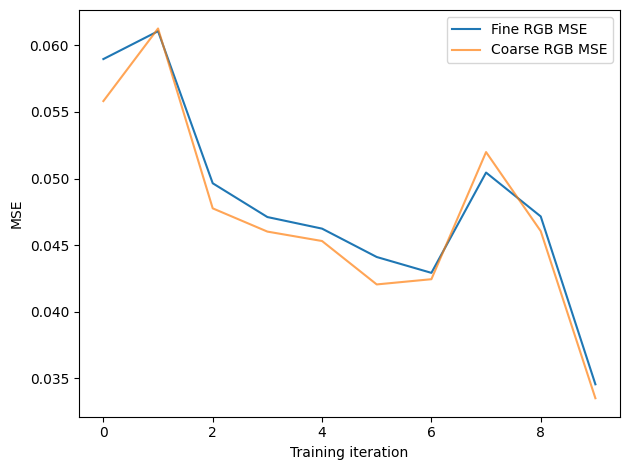

In [11]:
plt.plot(loss_history, label="Fine RGB MSE")
plt.plot(coarse_loss_history, label="Coarse RGB MSE", alpha=0.7)
plt.xlabel("Training iteration")
plt.ylabel("MSE")
plt.legend()
plt.tight_layout()
plt.savefig(output_dir / "loss.png", dpi=150)
plt.show()

## Test images

Render the original 23 held-out views and save predictions and targets for evaluation in `3-eval.ipynb`.

In [12]:
raysampler_grid = NDCMultinomialRaysampler(   
    image_height=image_height,   
    image_width=image_width,
    n_pts_per_ray=samples_per_ray,
    min_depth=min_depth,   
    max_depth=max_depth,
    stratified_sampling=False,  
).to(device)  
   




  

  

def render_image(camera):   
    with torch.no_grad():  
        rays = raysampler_grid(cameras=camera)
        rays = correct_ray_directions(rays, camera)  
  
    
        origins = rays.origins.reshape(-1, 3)   
        directions = rays.directions.reshape(-1, 3)  
        lengths = rays.lengths.reshape(-1, samples_per_ray)  
        xy = rays.xys.reshape(-1, 2)    

  
        image = torch.empty((image_height * image_width, 3))   



    
        for start in range(0, len(image), 1024):
            stop = start + 1024      
            chunk = RayBundle(
                origins=origins[None, start:stop],
                directions=directions[None, start:stop],  
                lengths=lengths[None, start:stop],   
                xys=xy[None, start:stop], 
                     
            )


            opacity, colour = model(chunk)   
            rendered = raymarcher(rays_densities=opacity, rays_features=colour)  
            image[start:stop] = rendered[0, :, :3].cpu()  



    return image.reshape(image_height, image_width, 3).clamp(0, 1)    

In [13]:
if RENDER_TEST:
    predictions = []
    test_names = [frame_ids[index] for index in test_indices.tolist()]
    render_start = time.perf_counter()

    for index in test_indices.tolist():
        image = render_image(target_cameras[index].to(device))
        predictions.append(image.numpy())
        print(frame_ids[index])

    predictions = np.stack(predictions)
    targets = target_images[test_indices].numpy()
    np.savez_compressed(output_dir / "poster_test_images.npz",
                        predictions=predictions, targets=targets,
                        frame_ids=np.array(test_names))
    render_time = time.perf_counter() - render_start
    if (output_dir / "run_info.json").exists():
        with (output_dir / "run_info.json").open() as file:
            run_info = json.load(file)
        run_info["render_test_seconds"] = render_time
        with (output_dir / "run_info.json").open("w") as file:
            json.dump(run_info, file, indent=2)

In [14]:
if RENDER_TEST:
    fig, axes = plt.subplots(2, 3, figsize=(8, 9))
    for column, position in enumerate([0, 11, 22]):
        axes[0, column].imshow(targets[position])
        axes[0, column].set_title(test_names[position])
        axes[1, column].imshow(predictions[position])
        axes[1, column].set_title("Prediction")
        axes[0, column].axis("off")
        axes[1, column].axis("off")
    plt.tight_layout()
    plt.savefig(output_dir / "comparison.png", dpi=150)
    plt.show()